# Mission and use case

**Mission.** With Umoja Health Connect, I want to enhance access to health services for underserved and rural communities all over Africa.

**Use case.** Predicts a country's under-5 mortality rate (deaths per 1,000 live births) using health service coverage and development measures such as immunization, health expenditure, water, sanitation and electricity.

**Who uses it and what for.** The prediction can be used to guide health ministry analysts and the Umoja Health Connect programme planners in targeting health services that are most closely linked to high child mortality rates and interventions to reduce child mortality in Africa.

**Limits.** Data is not facility-specific and this is an association, not causation model. It is a first step towards facility-level work.

In [7]:
import pandas as pd

df = pd.read_csv("africa_child_mortality.csv")
print(df.shape)

(2160, 21)


In [8]:
df.head()

,continent,subregion,country,iso3,year,wb_region,income_level,income_level_id,lending_type,"Mortality rate, under-5 (per 1,000 live births)",...,Urban population growth (annual %),People using at least basic sanitation services (% of population),People using at least basic drinking water services (% of population),Access to electricity (% of population),Current health expenditure per capita (current US$),"Immunization, DPT (% of children ages 12-23 months)","Immunization, measles (% of children ages 12-23 months)",GDP per capita (constant 2015 US$),"Primary completion rate, total (% of relevant age group)","Maternal mortality ratio (modeled estimate, per 100,000 live births)"
0,Africa,Central Africa,Angola,AGO,1985,Sub-Saharan Africa,Lower middle income,LMC,IBRD,217.3,...,8.308400,33.800408,37.842237,24.2,13.159986,8,44,2896.783036,32.571171,877
1,Africa,Central Africa,Angola,AGO,1986,Sub-Saharan Africa,Lower middle income,LMC,IBRD,215.6,...,8.064899,33.800408,37.842237,24.2,13.159986,10,44,2874.860184,32.571171,864
2,Africa,Central Africa,Angola,AGO,1987,Sub-Saharan Africa,Lower middle income,LMC,IBRD,214.6,...,7.731405,33.800408,37.842237,24.2,13.159986,10,55,2890.075476,32.571171,920
3,Africa,Central Africa,Angola,AGO,1988,Sub-Saharan Africa,Lower middle income,LMC,IBRD,213.8,...,7.468181,33.800408,37.842237,24.2,13.159986,12,56,2964.572345,32.571171,895
4,Africa,Central Africa,Angola,AGO,1989,Sub-Saharan Africa,Lower middle income,LMC,IBRD,213.2,...,7.283634,33.800408,37.842237,24.2,13.159986,18,48,2866.246114,32.571171,884


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 21 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   continent                                                              2160 non-null   str    
 1   subregion                                                              2160 non-null   str    
 2   country                                                                2160 non-null   str    
 3   iso3                                                                   2160 non-null   str    
 4   year                                                                   2160 non-null   int64  
 5   wb_region                                                              2160 non-null   str    
 6   income_level                                                           2160 non-null   str    
 7  

In [10]:
df.describe()

,year,"Mortality rate, under-5 (per 1,000 live births)",Urban population (% of total population),Urban population growth (annual %),People using at least basic sanitation services (% of population),People using at least basic drinking water services (% of population),Access to electricity (% of population),Current health expenditure per capita (current US$),"Immunization, DPT (% of children ages 12-23 months)","Immunization, measles (% of children ages 12-23 months)",GDP per capita (constant 2015 US$),"Primary completion rate, total (% of relevant age group)","Maternal mortality ratio (modeled estimate, per 100,000 live births)"
count,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000
mean,2004.500000,105.580556,39.561394,3.826653,36.178868,62.749104,39.596943,87.139327,71.040741,70.142130,2118.492650,62.070628,572.839815
std,11.546069,67.385020,18.042720,2.250973,26.473032,19.265651,30.670513,121.168570,22.686257,20.524496,2650.364086,24.133800,571.844951
min,1985.000000,9.800000,5.013454,-9.063466,2.965766,18.759061,0.533899,4.175786,3.000000,6.000000,169.787800,5.888460,17.000000
25%,1994.750000,55.375000,26.668866,2.623138,14.535058,48.368694,12.700000,17.661452,55.750000,57.000000,620.021060,42.631343,232.750000
50%,2004.500000,92.350000,38.233892,3.694447,28.064122,61.174222,32.150000,38.468132,77.000000,73.000000,1088.889636,61.926460,479.500000
75%,2014.250000,145.200000,50.516475,4.708002,50.251916,76.665164,60.300000,88.607752,90.000000,87.000000,2290.338533,81.127170,741.000000
max,2024.000000,780.900000,91.863209,32.298521,99.700000,99.926546,100.000000,766.287781,99.000000,99.000000,19481.646105,156.167176,8045.000000


In [11]:
df.isna().sum()

continent                                                                0
subregion                                                                0
country                                                                  0
iso3                                                                     0
year                                                                     0
wb_region                                                                0
income_level                                                             0
income_level_id                                                          0
lending_type                                                             0
Mortality rate, under-5 (per 1,000 live births)                          0
Urban population (% of total population)                                 0
Urban population growth (annual %)                                       0
People using at least basic sanitation services (% of population)        0
People using at least bas

In [12]:
df = df.rename(columns={
    "Mortality rate, under-5 (per 1,000 live births)": "u5_mortality",
    "Urban population (% of total population)": "urban_pop_pct",
    "Urban population growth (annual %)": "urban_growth",
    "People using at least basic sanitation services (% of population)": "sanitation_pct",
    "People using at least basic drinking water services (% of population)": "water_pct",
    "Access to electricity (% of population)": "electricity_pct",
    "Current health expenditure per capita (current US$)": "health_exp_per_capita",
    "Immunization, DPT (% of children ages 12-23 months)": "dpt_immunization",
    "Immunization, measles (% of children ages 12-23 months)": "measles_immunization",
    "GDP per capita (constant 2015 US$)": "gdp_per_capita",
    "Primary completion rate, total (% of relevant age group)": "primary_completion",
    "Maternal mortality ratio (modeled estimate, per 100,000 live births)": "maternal_mortality",
})
df.columns.tolist()

['continent',
 'subregion',
 'country',
 'iso3',
 'year',
 'wb_region',
 'income_level',
 'income_level_id',
 'lending_type',
 'u5_mortality',
 'urban_pop_pct',
 'urban_growth',
 'sanitation_pct',
 'water_pct',
 'electricity_pct',
 'health_exp_per_capita',
 'dpt_immunization',
 'measles_immunization',
 'gdp_per_capita',
 'primary_completion',
 'maternal_mortality']

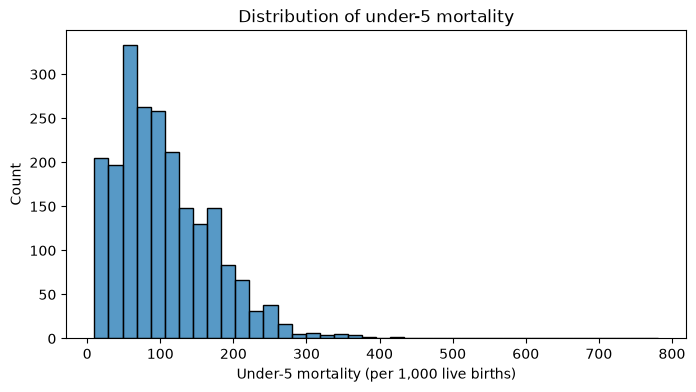

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(df["u5_mortality"], bins=40)
plt.xlabel("Under-5 mortality (per 1,000 live births)")
plt.title("Distribution of under-5 mortality")
plt.show()

**What it shows.** Under-5 mortality is right-skewed: most country-years sit between about 30 and 200 deaths per 1,000 live births, with the highest bar near 60 to 70. A small number of rows have extremely high values, stretching out past 700.

**What I decided.** These high values are real observations, not errors, and my use case is about the places with the highest child mortality, so I will keep them rather than delete them. I expect they will raise the error of the linear models more than the tree-based models, so I will check this when I compare test MSE.

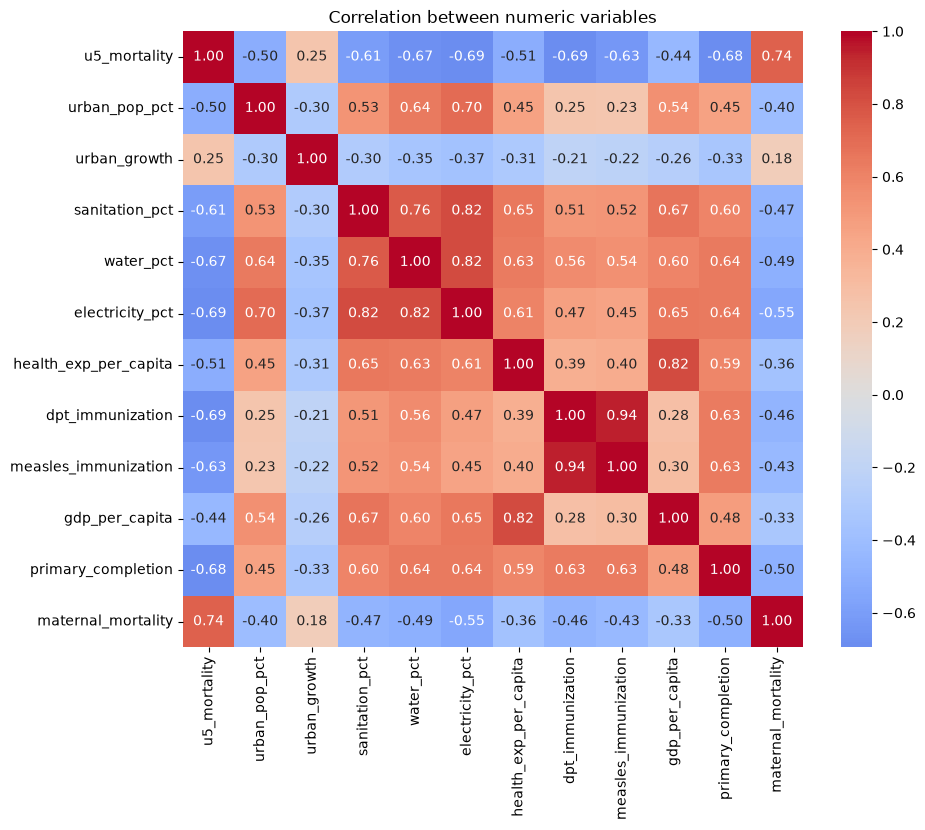

In [14]:
num_cols = df.select_dtypes("number").columns.drop("year")

plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric variables")
plt.show()

**What it shows.** Child mortality is most strongly linked to electricity, DPT immunization, school completion and water access (around -0.7), so countries with more coverage have fewer child deaths. Maternal mortality is linked the most (+0.74). Many of the development variables also move together, for example DPT and measles (0.94), so they repeat the same information.

**What I decided.** I will drop maternal mortality because it is too closely tied to child mortality, and I will keep DPT and drop measles because they say almost the same thing.